In [10]:
import concurrent.futures
import io
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
from PIL import Image, ImageChops
import requests
import torch
from tqdm.auto import tqdm
from transformers import CLIPModel, CLIPProcessor



# LOAD unsplashed photos #

In [8]:
from pathlib import Path
import glob
import pandas as pd
import numpy as np

# 1. Set path to where your .tsv000 files live
# If your files are in a subfolder like 'data/' or 'unsplash/', change this path accordingly:
data_path = Path("data/unsplash-research-dataset-lite-latest")  # or Path(".") if they are in the project root

# For 02807, the most important tables are 'photos' and 'keywords'
documents = ['photos', 'keywords', 'collections', 'conversions', 'colors']
datasets = {}

for doc in documents:
    # Match both .tsv* and .csv* file patterns
    files = sorted(glob.glob(str(data_path / f"{doc}.*sv*")))
    
    if not files:
        print(f"Warning: No files found for '{doc}' in {data_path}")
        continue
        
    subsets = []
    for filename in files:
        # Unsplash files are tab-separated
        df = pd.read_csv(filename, sep='\t', header=0, low_memory=False)
        subsets.append(df)
        
    datasets[doc] = pd.concat(subsets, axis=0, ignore_index=True)
    print(f"Loaded '{doc}': {datasets[doc].shape[0]:,} rows, {datasets[doc].shape[1]} columns")

Loaded 'photos': 25,000 rows, 31 columns
Loaded 'keywords': 909,055 rows, 8 columns
Loaded 'collections': 2,205,216 rows, 5 columns
Loaded 'conversions': 6,002,124 rows, 9 columns
Loaded 'colors': 245,677 rows, 8 columns


In [9]:
photos_df = datasets['photos']
keywords_df = datasets['keywords']

print("--- PHOTOS TABLE COLUMNS ---")
print(photos_df.columns.tolist())

print("\n--- SAMPLE EXIF & IMAGE DATA ---")
exif_cols = [c for c in photos_df.columns if any(k in c.lower() for k in ['exif', 'camera', 'iso', 'aperture', 'focal', 'url', 'id'])]
print(photos_df[exif_cols].head())

print("\n--- SAMPLE KEYWORDS ---")
print(keywords_df.head())

--- PHOTOS TABLE COLUMNS ---
['photo_id', 'photo_url', 'photo_image_url', 'photo_submitted_at', 'photo_featured', 'photo_width', 'photo_height', 'photo_aspect_ratio', 'photo_description', 'photographer_username', 'photographer_first_name', 'photographer_last_name', 'exif_camera_make', 'exif_camera_model', 'exif_iso', 'exif_aperture_value', 'exif_focal_length', 'exif_exposure_time', 'photo_location_name', 'photo_location_latitude', 'photo_location_longitude', 'photo_location_country', 'photo_location_city', 'stats_views', 'stats_downloads', 'ai_description', 'ai_primary_landmark_name', 'ai_primary_landmark_latitude', 'ai_primary_landmark_longitude', 'ai_primary_landmark_confidence', 'blur_hash']

--- SAMPLE EXIF & IMAGE DATA ---
      photo_id                                photo_url  \
0  luPOnViYl7I  https://unsplash.com/photos/luPOnViYl7I   
1  OdAqbedkfiA  https://unsplash.com/photos/OdAqbedkfiA   
2  w9UQ02x-QsU  https://unsplash.com/photos/w9UQ02x-QsU   
3  491PQ04olSg  https://un

In [11]:
# ----------------------------------------------------------------------
# 1. LOAD TRAINED MODEL & SCALER
# ----------------------------------------------------------------------
artifacts = joblib.load("models/aesthetic_ridge_model.pkl")
ridge_model = artifacts["model"]
scaler = artifacts["scaler"]

In [12]:
# ----------------------------------------------------------------------
# 2. SETUP HARDWARE & FROZEN CLIP BACKBONE
# ----------------------------------------------------------------------
device = (
    "cuda"
    if torch.cuda.is_available()
    else ("mps" if torch.backends.mps.is_available() else "cpu")
)
print(f"Using device: {device}")

model_id = "openai/clip-vit-base-patch32"
clip_model = CLIPModel.from_pretrained(model_id).to(device).eval()
processor = CLIPProcessor.from_pretrained(model_id)

Using device: cpu


Loading weights: 100%|██████████| 398/398 [00:00<00:00, 18953.75it/s]


In [13]:
# ----------------------------------------------------------------------
# 3. STRUCTURAL FEATURE EXTRACTION (Exact AVA specifications)
# ----------------------------------------------------------------------
def trim_uniform_borders(img: Image.Image, tolerance: int = 15) -> Image.Image:
  bg = Image.new(img.mode, img.size, img.getpixel((0, 0)))
  diff = ImageChops.difference(img, bg)
  diff = ImageChops.add(diff, diff, 2.0, -tolerance)
  bbox = diff.getbbox()
  return img.crop(bbox) if bbox else img


def extract_structural_features(img: Image.Image) -> list[float]:
  arr = np.asarray(img.resize((128, 128)), dtype=np.float32) / 255.0
  r, g, b = arr[:, :, 0], arr[:, :, 1], arr[:, :, 2]

  lum = 0.299 * r + 0.587 * g + 0.114 * b
  contrast = float(np.std(lum))
  brightness = float(np.mean(lum))

  center_lum = float(np.std(lum[32:96, 32:96]))
  center_ratio = center_lum / (contrast + 1e-5)

  return [
      brightness,
      contrast,
      center_ratio,
      float(np.mean(r)),
      float(np.mean(g)),
      float(np.mean(b)),
      float(np.std(r)),
      float(np.std(g)),
      float(np.std(b)),
  ]

In [15]:
# ----------------------------------------------------------------------
# 4. FAST THUMBNAIL DOWNLOADER
# ----------------------------------------------------------------------
session = requests.Session()


def download_single_image(row):
  photo_id = row["photo_id"]
  # Append ?w=400 to request a lightweight thumbnail from Unsplash CDN
  base_url = row["photo_image_url"]
  url = (
      f"{base_url}?w=400&q=80"
      if "?" not in base_url
      else f"{base_url}&w=400&q=80"
  )

  try:
    resp = session.get(url, timeout=10)
    if resp.status_code == 200:
      img = Image.open(io.BytesIO(resp.content)).convert("RGB")
      img = trim_uniform_borders(img)
      w, h = img.size
      aspect_ratio = w / max(h, 1)
      struct_12 = extract_structural_features(img) + [
          aspect_ratio,
          float(w),
          float(h),
      ]
      return {
          "photo_id": photo_id,
          "img": img,
          "struct": struct_12,
          "success": True,
      }
  except Exception:
    pass
  return {"photo_id": photo_id, "success": False}

# Do the predictions #

In [16]:
# ----------------------------------------------------------------------
# 5. INFERENCE LOOP OVER UNSPLASH PHOTOS
# ----------------------------------------------------------------------
# Use the photos table loaded in the previous step
photos_df = datasets["photos"]  # Contains ~25k rows

# For testing you can slice: target_photos = photos_df.head(100)
target_photos = photos_df

BATCH_SIZE = 64
NUM_WORKERS = 16  # Thread pool for fast async image downloading

records_to_process = target_photos[[
    "photo_id", "photo_image_url"
]].to_dict("records")
results = []

pbar = tqdm(total=len(records_to_process), desc="Predicting Unsplash Ratings")

# Process in chunks of (BATCH_SIZE * 4) to balance I/O and GPU throughput
CHUNK_SIZE = BATCH_SIZE * 4
for i in range(0, len(records_to_process), CHUNK_SIZE):
  chunk = records_to_process[i : i + CHUNK_SIZE]

  # Download chunk in parallel threads
  downloaded_items = []
  with concurrent.futures.ThreadPoolExecutor(
      max_workers=NUM_WORKERS
  ) as executor:
    for item in executor.map(download_single_image, chunk):
      if item["success"]:
        downloaded_items.append(item)

  # Run mini-batches through CLIP + Scorer
  for b in range(0, len(downloaded_items), BATCH_SIZE):
    batch = downloaded_items[b : b + BATCH_SIZE]
    batch_imgs = [x["img"] for x in batch]
    batch_struct = [x["struct"] for x in batch]
    batch_ids = [x["photo_id"] for x in batch]

    with torch.no_grad():
      # 1. CLIP 512-dim embedding
      inputs = processor(images=batch_imgs, return_tensors="pt").to(device)
      vision_out = clip_model.vision_model(pixel_values=inputs["pixel_values"])
      embeds = clip_model.visual_projection(vision_out.pooler_output)
      embeds = torch.nn.functional.normalize(embeds, p=2, dim=-1)
      clip_np = embeds.cpu().numpy().astype(np.float32)

      # 2. Scale 12-dim structural features with saved AVA scaler
      struct_np = np.array(batch_struct, dtype=np.float32)
      struct_scaled = scaler.transform(struct_np)

      # 3. Concatenate into (B, 524)
      X_combined = np.hstack([clip_np, struct_scaled])

      # 4. Predict aesthetic score
      preds = ridge_model.predict(X_combined)

      for pid, score, emb in zip(batch_ids, preds, clip_np):
        results.append({
            "photo_id": pid,
            "predicted_aesthetic_score": float(score),
            "clip_embedding": emb.tolist(),
        })

  pbar.update(len(chunk))

pbar.close()

Predicting Unsplash Ratings: 100%|██████████| 25000/25000 [32:00<00:00, 13.02it/s]


# Lets see the highest rated pictures #

In [17]:
# ----------------------------------------------------------------------
# 6. SAVE PREDICTIONS & MERGE METADATA
# ----------------------------------------------------------------------
predictions_df = pd.DataFrame(results)

# Discretize continuous predictions into 3 balanced bins for Week 5
predictions_df["aesthetic_bin"] = pd.qcut(
    predictions_df["predicted_aesthetic_score"],
    q=[0.0, 0.25, 0.75, 1.0],
    labels=["Low_Aesthetic", "Average_Aesthetic", "High_Aesthetic"],
)

# Merge back with photos metadata (EXIF fields)
final_unsplash_df = photos_df.merge(predictions_df, on="photo_id", how="inner")

output_path = Path("data/unsplash_scored_25k.parquet")
final_unsplash_df.to_parquet(output_path, index=False)
print(f"\nCompleted! Saved {len(final_unsplash_df)} scored photos to {output_path}")


Completed! Saved 24993 scored photos to data\unsplash_scored_25k.parquet


--- TOP 3 AESTHETIC UNSPLASH PHOTOS ---

Photo ID: NY5uagc167k
Predicted Score: 6.700 | Bin: High_Aesthetic
Camera: SONY ILCE-7RM4
Aperture: f/9 | ISO: 200.0


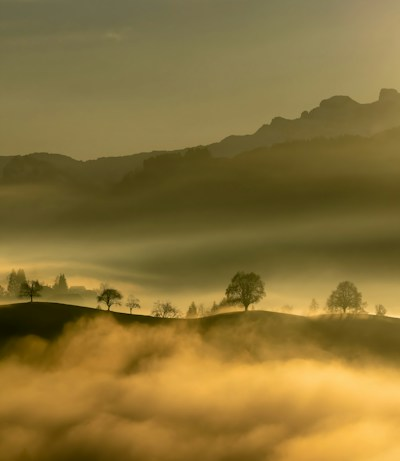


Photo ID: kCJa4GoaRxc
Predicted Score: 6.670 | Bin: High_Aesthetic
Camera: SONY ILCE-7M3
Aperture: f/22.0 | ISO: 50.0


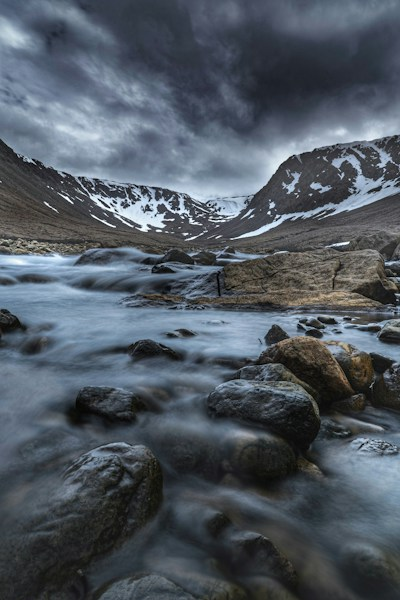


Photo ID: v41Z5HCahzo
Predicted Score: 6.658 | Bin: High_Aesthetic
Camera: NIKON CORPORATION NIKON D750
Aperture: f/1.8 | ISO: 6400.0


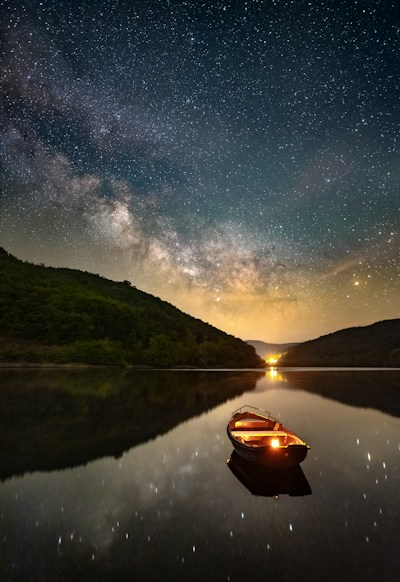

In [18]:
from IPython.display import display

top_photos = final_unsplash_df.sort_values(
    by="predicted_aesthetic_score", ascending=False
).head(3)

print("--- TOP 3 AESTHETIC UNSPLASH PHOTOS ---")
for _, r in top_photos.iterrows():
  print(f"\nPhoto ID: {r['photo_id']}")
  print(
      f"Predicted Score: {r['predicted_aesthetic_score']:.3f} | Bin:"
      f" {r['aesthetic_bin']}"
  )
  print(
      f"Camera: {r.get('exif_camera_make', 'N/A')} {r.get('exif_camera_model', '')}"
  )
  print(
      f"Aperture: f/{r.get('exif_aperture_value', 'N/A')} | ISO:"
      f" {r.get('exif_iso', 'N/A')}"
  )

  # Render image directly in notebook
  resp = requests.get(f"{r['photo_image_url']}?w=400")
  display(Image.open(io.BytesIO(resp.content)))

# Lets see pictures from each prediction score #

DISPLAYING 3 PHOTOS FOR EACH INTEGER SCORE: [3, 4, 5, 6, 7]

>>> TARGET SCORE: 3 <<<


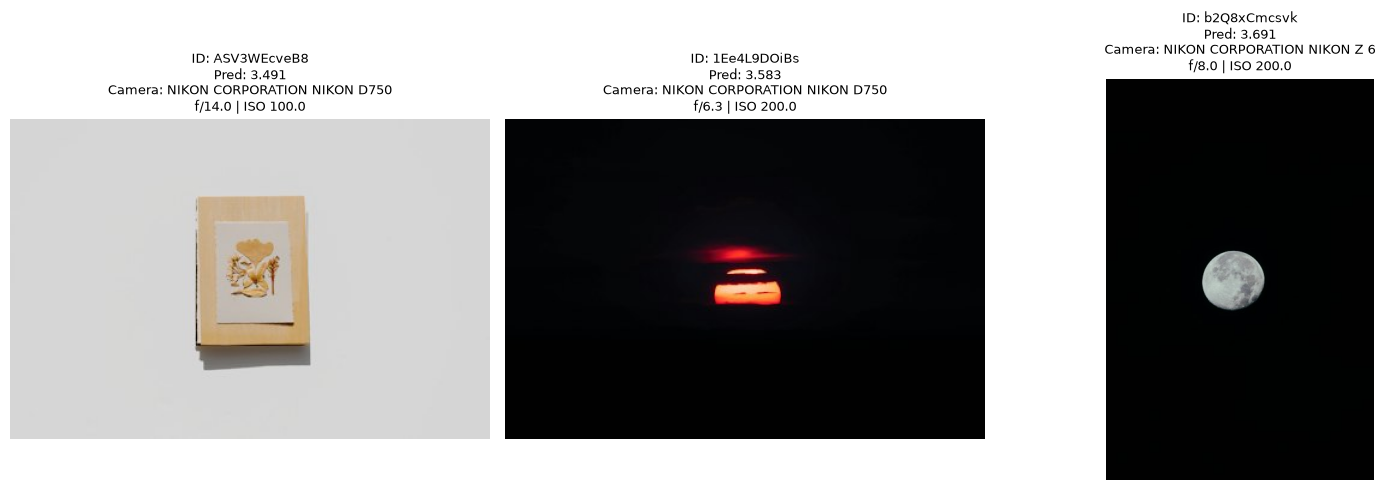

-------------------------------------------------------------------------------------

>>> TARGET SCORE: 4 <<<


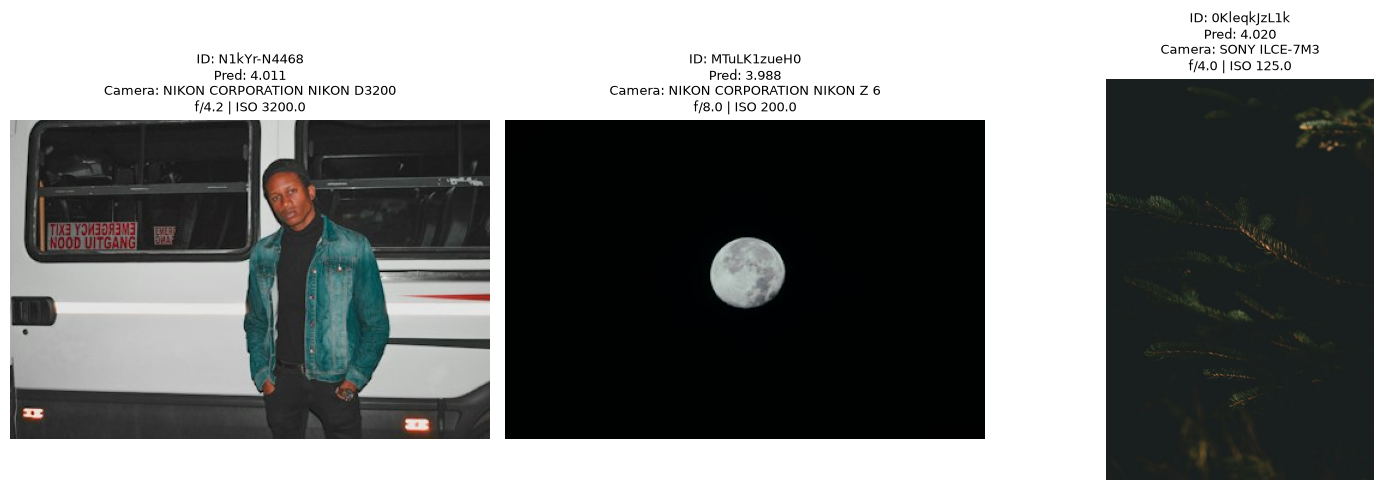

-------------------------------------------------------------------------------------

>>> TARGET SCORE: 5 <<<


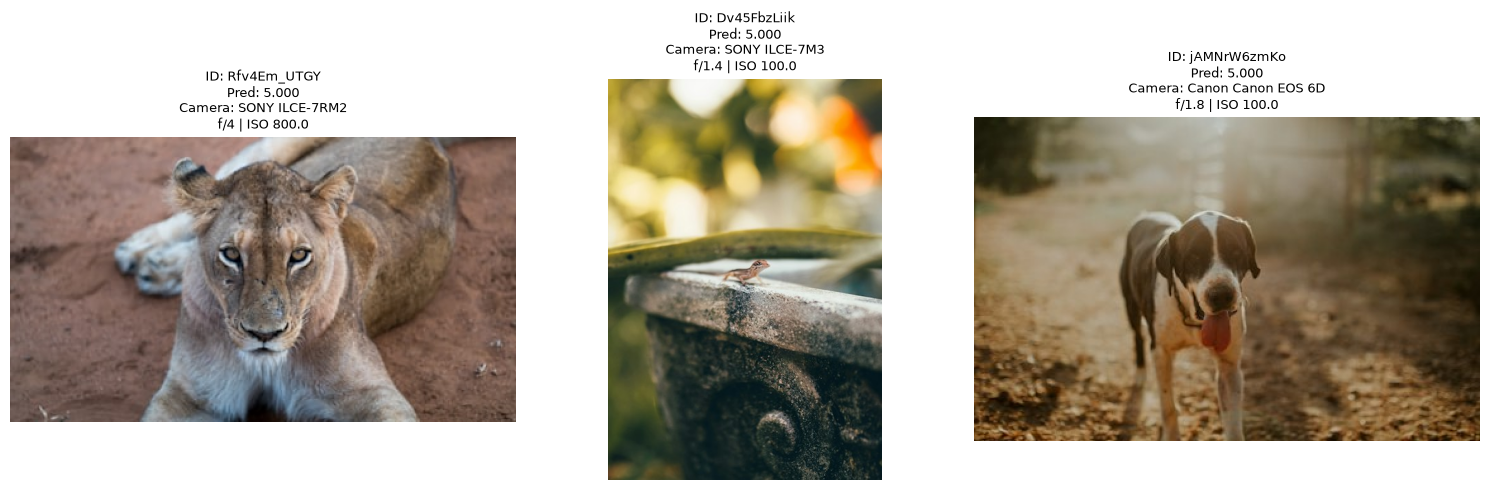

-------------------------------------------------------------------------------------

>>> TARGET SCORE: 6 <<<


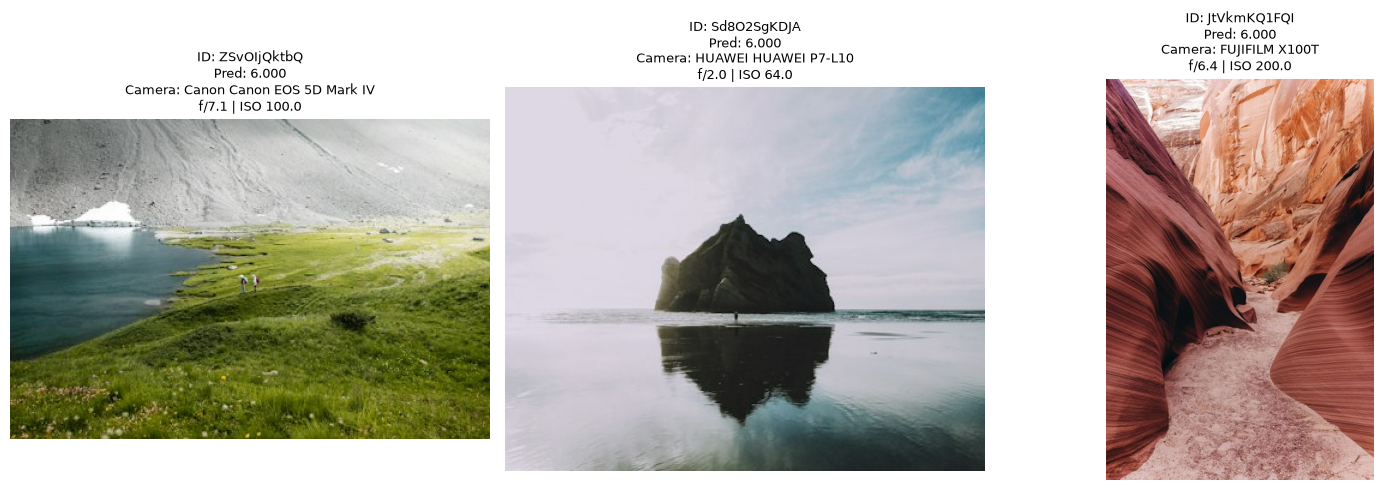

-------------------------------------------------------------------------------------

>>> TARGET SCORE: 7 <<<


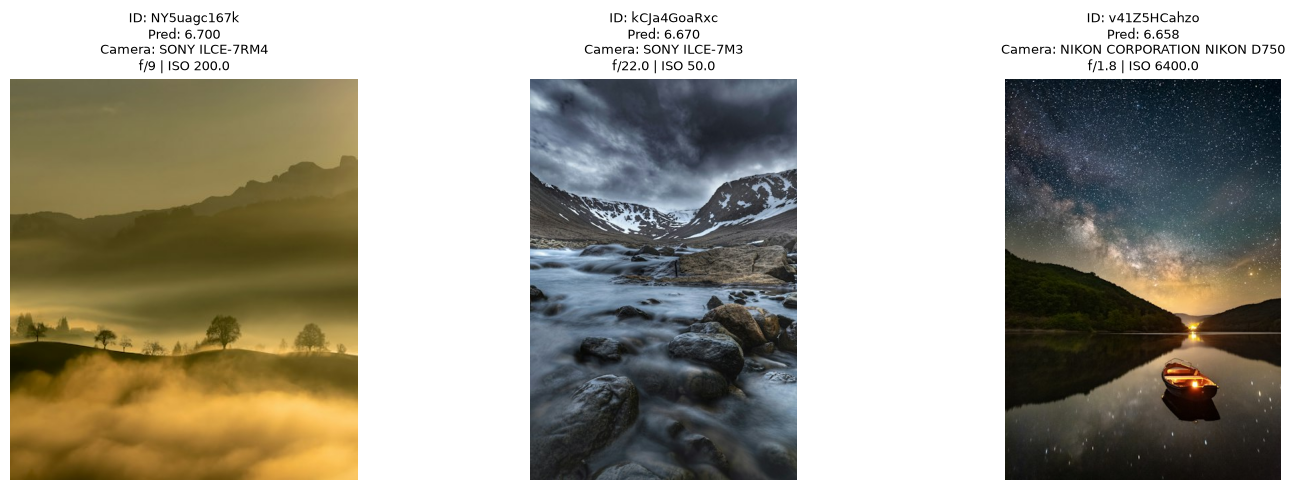

-------------------------------------------------------------------------------------


In [22]:
import io
import matplotlib.pyplot as plt
from PIL import Image
import requests

session = requests.Session()

# 1. Determine valid integer targets present in the predicted distribution
min_score = int(np.floor(final_unsplash_df["predicted_aesthetic_score"].min()))
max_score = int(np.ceil(final_unsplash_df["predicted_aesthetic_score"].max()))
target_scores = list(range(max(1, min_score), min(11, max_score + 1)))

K_PER_SCORE = 3

print("=" * 85)
print(f"DISPLAYING {K_PER_SCORE} PHOTOS FOR EACH INTEGER SCORE: {target_scores}")
print("=" * 85)

for target in target_scores:
  # Compute absolute distance from this integer
  df_temp = final_unsplash_df.copy()
  df_temp["diff"] = (df_temp["predicted_aesthetic_score"] - target).abs()

  # Select top 3 closest unique photos
  top_matches = df_temp.nsmallest(K_PER_SCORE, "diff")

  print(f"\n>>> TARGET SCORE: {target} <<<")

  fig, axes = plt.subplots(1, K_PER_SCORE, figsize=(15, 5))
  if K_PER_SCORE == 1:
    axes = [axes]

  for i, (_, row) in enumerate(top_matches.iterrows()):
    photo_id = row["photo_id"]
    score = row["predicted_aesthetic_score"]
    make = row.get("exif_camera_make", "N/A")
    model = row.get("exif_camera_model", "")
    aperture = row.get("exif_aperture_value", "N/A")
    iso = row.get("exif_iso", "N/A")
    base_url = row.get("photo_image_url", "")

    # Download thumbnail
    img = None
    if base_url:
      try:
        url = (
            f"{base_url}?w=400&q=80"
            if "?" not in base_url
            else f"{base_url}&w=400&q=80"
        )
        resp = session.get(url, timeout=10)
        if resp.status_code == 200:
          img = Image.open(io.BytesIO(resp.content))
      except Exception:
        pass

    ax = axes[i]
    if img:
      ax.imshow(img)
      ax.axis("off")
      title = (
          f"ID: {photo_id}\nPred: {score:.3f}\nCamera: {make} {model}\nf/{aperture}"
          f" | ISO {iso}"
      )
      ax.set_title(title, fontsize=9)
    else:
      ax.text(0.5, 0.5, "Image load failed", ha="center", va="center")
      ax.axis("off")

  plt.tight_layout()
  plt.show()
  print("-" * 85)

# Saving prediction data #


In [23]:
from pathlib import Path

# Create data directory if it doesn't exist
output_dir = Path("data")
output_dir.mkdir(parents=True, exist_ok=True)

parquet_save_path = output_dir / "unsplash_scored_predictions.parquet"

# Save DataFrame to Parquet
final_unsplash_df.to_parquet(parquet_save_path, index=False)
print(f"Saved {len(final_unsplash_df):,} scored rows to: {parquet_save_path}")

Saved 24,993 scored rows to: data\unsplash_scored_predictions.parquet
